# Week 2 - Preprocessing, part 2

# 1. Lesson: None

# 2. Weekly graph question

The Storytelling With Data book mentions planning on a "Who, What, and How" for your data story.  Write down a possible Who, What, and How for your data, using the ideas in the book.

In [226]:
#Utilizing the project dataset aligned to Population Health, Chronic Disease, and Prevention the planning strategy is as follows:

#Who: The audience for this analysis would be for healthcare system planners and policy makers. These audiences need to understand the type of chronic disease with the greatest impact, which populations are most affected, and whether healthcare infrastructure is adequate to meet current and future demand. 

#What: The goal of the analysis will identify the type of chronic disease with the greatest impact, provide insight into the behavioral and access related factors contributing to differences in outcomes, examine patterns using clinical measurements, and evaluate whether healthcare capacity is adequate to meet the needs of affected populations.

#How: The analysis will use the Behavioral Risk Factor Surveillance System (BRFSS) 2024 to examine chronic disease patterns, health behaviors, demographics, and access to care challenges. The 2021 – 2023 National Health and Nutrition Examination Survey (NHANES) will be used to support the clinical patterns found in the BRFSS. The 2023 CMS Medicare Provider Statistics will be used to assess healthcare resource availability across states. The findings will be presented through demographic analysis and visualizations designed to identify potential gaps between chronic disease related needs and available healthcare resources.


# 3. Homework - work with your chosen project datasets this semester

In [227]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

from IPython.core.pylabtools import figsize
from langchain.agents.format_scratchpad import format_log_to_str
from matplotlib.sphinxext.figmpl_directive import depart_figmpl_html
from networkx import display
from xlwt.ExcelMagic import ptgLT

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

### Here are some types of analysis you can do  Use Google, documentation, and ChatGPT to help you:

- Summarize the datasets using info() and describe()

- Are there any duplicate rows?

- Are there any duplicate values in a given column (when this would be inappropriate?)

- What are the mean, median, and mode of each column?

- Are there any missing or null values?

    - Do you want to fill in the missing value with a mean value?  A value of your choice?  Remove that row?

- Identify any other inconsistent data (e.g. someone seems to be taking an action before they are born.)

- Encode any categorical variables (e.g. with one-hot encoding.)

### Conclusions:

- Are the data usable?  If not, find some new data!

- Do you need to modify or correct the data in some way?

- Is there any class imbalance?  (Categories that have many more items than other categories).

In [228]:

file_path = r"MDCR PROVIDERS_CPS19PRV_2023.xlsx"
raw_df = pd.read_excel(file_path, sheet_name="MDCR PROVIDERS 6_CPS_19PRV", header=None)

raw_df.columns=raw_df.iloc[3]
df = raw_df.iloc[4:].reset_index(drop=True)

df.columns = ['Specialty', '2019', '2020', '2021', '2022', '2023']
df = df.dropna(how='all')

df= df[df['Specialty'] != 'BLANK']

df['All Physician Specialties'] = pd.NA

categories = ['Primary Care', 'Medical', 'Surgicial', 'Radiology', 'Obstetrics-Gynecology', 'Psychiatry', 'Non-Physician Practitioners', 'Limited Licensed Practitioners', 'Other Providers/Suppliers']

current_category = None

for idx, row in df.iterrows():
    if row['Specialty'] in categories:
        current_category = row['Specialty']
        
    df.loc[idx, 'All Physician Specialties'] = current_category
    
df = df[~df['Specialty'].isin(categories)]

remove_rows = ['Total All Specialties', 'All Physician Specialties']

df = df[~df['Specialty'].isin(remove_rows)]

df = df.reset_index(drop=True)

df = df[~df['Specialty'].astype(str).str.startswith(('NOTES:', 'SOURCE:', 'other providers', 'from counts'))]

print(df)

df.to_excel("CMS_Providers_Cleaned.xlsx",index=False)

                                            Specialty    2019      2020  \
0                                     Family Practice   95358   95263.0   
1                                    General Practice    8648    8215.0   
2                                   Internal Medicine  112362  110443.0   
3                                  Pediatric Medicine   10887   11087.0   
4                                  Addiction Medicine     379     400.0   
..                                                ...     ...       ...   
91                             Medical Supply Company    9465    9364.0   
92                          Opioid Treatment Programs      --     920.0   
93                                          Pharmacy    48739   48044.0   
94    Portable X-Ray Supplier (Billing Independently)     315     308.0   
95  All Other Providers/Suppliers, Not Elsewhere C...    2513    2376.0   

        2021      2022      2023  All Physician Specialties  
0    94830.0   94832.0   95349.0     

CMS Providers Dataset

In [229]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 96 entries, 0 to 95
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Specialty                  96 non-null     object 
 1   2019                       95 non-null     object 
 2   2020                       95 non-null     float64
 3   2021                       95 non-null     float64
 4   2022                       95 non-null     float64
 5   2023                       95 non-null     float64
 6   All Physician Specialties  96 non-null     object 
dtypes: float64(4), object(3)
memory usage: 6.0+ KB


In [230]:
df['2019']=pd.to_numeric(df['2019'], errors='coerce')
df.describe()

,2019,2020,2021,2022,2023
count,92.000000,95.000000,95.000000,95.000000,95.000000
mean,15532.445652,15319.778947,15746.557895,16189.010526,16550.136842
std,26643.038483,27354.437248,28744.438997,30384.431661,31918.098661
min,46.000000,40.000000,50.000000,46.000000,44.000000
25%,1686.250000,1631.500000,1615.500000,1600.000000,1602.500000
50%,4986.000000,4336.000000,4647.000000,5067.000000,5236.000000
75%,15260.250000,13969.000000,14086.000000,14436.000000,15315.500000
max,163497.000000,177074.000000,193281.000000,211517.000000,227687.000000


In [231]:
df.duplicated().sum()

np.int64(0)

In [232]:
summary_stats = pd.DataFrame ({
    'Mean': df[['2019','2020','2021','2022','2023']].mean(),
    'Median': df[['2019','2020','2021','2022','2023']].median(),
    'Mode': df[['2019','2020','2021','2022','2023']].mode().iloc[0]
})
print(summary_stats)

              Mean  Median    Mode
2019  15532.445652  4986.0    46.0
2020  15319.778947  4336.0  2510.0
2021  15746.557895  4647.0    50.0
2022  16189.010526  5067.0    46.0
2023  16550.136842  5236.0    44.0


In [233]:
missing = df.isnull().sum()
print(missing)

Specialty                    0
2019                         4
2020                         1
2021                         1
2022                         1
2023                         1
All Physician Specialties    0
dtype: int64


In [234]:
#Handling Missing Values

for year in ['2019','2020','2021','2022','2023']:
    df[year] = df[year].fillna(df[year].median())
    
missing = df.isnull().sum()
print(missing)    

Specialty                    0
2019                         0
2020                         0
2021                         0
2022                         0
2023                         0
All Physician Specialties    0
dtype: int64


In [235]:
#One-Hot Encoding

df_encoded = pd.get_dummies(df, columns=['All Physician Specialties'])
print(df_encoded.head())

            Specialty      2019      2020      2021      2022      2023  \
0     Family Practice   95358.0   95263.0   94830.0   94832.0   95349.0   
1    General Practice    8648.0    8215.0    7845.0    7508.0    7238.0   
2   Internal Medicine  112362.0  110443.0  109202.0  109287.0  109774.0   
3  Pediatric Medicine   10887.0   11087.0   11684.0   10907.0   10350.0   
4  Addiction Medicine     379.0     400.0     417.0     437.0     477.0   

   All Physician Specialties_Limited Licensed Practitioners  \
0                                              False          
1                                              False          
2                                              False          
3                                              False          
4                                              False          

   All Physician Specialties_Medical  \
0                              False   
1                              False   
2                              False   
3         

In [236]:
#Imbalance Output

df['All Physician Specialties'].value_counts()

All Physician Specialties
Medical                           52
Non-Physician Practitioners       15
Other Providers/Suppliers         12
Limited Licensed Practitioners     5
Primary Care                       4
Radiology                          4
Obstetrics-Gynecology              2
Psychiatry                         2
Name: count, dtype: int64

In [237]:
#Conclusion

# This CMS Medicare Provider Statistics dataset is well suited for analyzing healthcare workforce capacity. No duplicate records were found, and only a small number of values were missing in the dataset. Descriptive statistics show that provider counts vary across specialties. In 2023, the median count was 5,236 while the average provider count was 16,550, suggesting that a small number of specialties have very large provider populations. These findings highlight differences in workforce distribution across specialties. Overall, the dataset provides valuable insight into healthcare provider availability and can support analysis aimed at determining whether healthcare workforce is sufficiently positioned to meet current and future population health needs.

BRFSS Dataset

In [238]:
#Data

df_brfss = pd.read_csv(r"BRFSS.csv")

df_brfss.shape


(337894, 301)

In [239]:
#Info
df_brfss.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 337894 entries, 0 to 337893
Columns: 301 entries, _STATE to _AIDTST4
dtypes: float64(171), int64(130)
memory usage: 776.0 MB


In [240]:
#Duplicated
df_brfss.duplicated().sum()

np.int64(0)

In [241]:
df_brfss.isnull().sum().sort_values(ascending=False).head(20)

_AIDTST4    1
_PNEUMO3    1
_FLSHOT7    1
_RFDRHV9    1
_DRNKWK3    1
_RFBING6    1
DROCDY4_    1
_CRCREC3    1
_SBONTI2    1
_VIRCOL2    1
_STOLDN2    1
_RFBLDS6    1
_SGMS102    1
_SGMSCP2    1
_HADSIGM    1
_CLNSCP2    1
_HADCOLN    1
_PAPHPV1    1
_HPV5YR1    1
_RFPAP37    1
dtype: int64

In [242]:
#Describe
df_brfss.describe()

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,PVTRESD1,COLGHOUS,STATERE1,CELPHON1,LADULT1,NUMADULT,RESPSLC1,LANDSEX3,SAFETIME,CTELNUM1,CELLFON5,CADULT1,CELLSEX3,PVTRESD3,CCLGHOUS,CSTATE1,LANDLINE,HHADULT,SEXVAR,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,PRIMINS2,PERSDOC3,MEDCOST1,CHECKUP1,EXERANY2,LASTDEN4,RMVTETH4,CVDINFR4,CVDCRHD4,CVDSTRK3,ASTHMA3,ASTHNOW,CHCSCNC1,CHCOCNC1,CHCCOPD3,ADDEPEV3,CHCKDNY2,HAVARTH4,DIABETE4,DIABAGE4,MARITAL,EDUCA,RENTHOM1,NUMHHOL4,NUMPHON4,CPDEMO1C,VETERAN3,EMPLOY1,CHILDREN,INCOME3,PREGNANT,WEIGHT2,HEIGHT3,DEAF,BLIND,DECIDE,DIFFWALK,DIFFDRES,DIFFALON,HADMAM,HOWLONG,CERVSCRN,CRVCLCNC,CRVCLPAP,CRVCLHPV,HADHYST2,HADSIGM4,COLNSIGM,COLNTES1,SIGMTES1,LASTSIG4,COLNCNCR,VIRCOLO1,VCLNTES2,SMALSTOL,STOLTEST,STOOLDN2,BLDSTFIT,SDNATES1,SMOKE100,SMOKDAY2,USENOW3,ECIGNOW3,LCSFIRST,LCSNUMCG,LCSCTSC1,LCSSCNCR,LCSCTWHN,ALCDAY4,AVEDRNK4,DRNK3GE5,MAXDRNKS,FLUSHOT7,FLSHTMY3,IMFVPLA5,PNEUVAC4,HIVTST7,HIVTSTD3,HIVRISK5,PDIABTS1,PREDIAB2,DIABTYPE,INSULIN1,CHKHEMO3,EYEEXAM1,DIABEYE1,DIABEDU1,FEETSORE,ARTHEXER,SHINGLE2,HPVADVC4,HPVADSH1,TETANUS1,CNCRDIFF,CNCRAGE,CNCRTYP2,CSRVTRT3,CSRVDOC1,CSRVSUM,CSRVRTRN,CSRVINST,CSRVINSR,CSRVDEIN,CSRVCLIN,CSRVPAIN,CSRVCTL2,PSATEST1,PSATIME1,PCPSARS2,PSASUGS1,PCSTALK2,CIMEMLO1,CDWORRY,CDDISCU1,CDHOUS1,CDSOCIA1,CAREGIV1,CRGVREL5,CRGVPRB4,CRGVALZD,CRGVNURS,CRGVPER2,CRGVHOU2,CRGVHRS2,CRGVLNG2,ACEDEPRS,ACEDRINK,ACEDRUGS,ACEPRISN,ACEDIVRC,ACEPUNCH,ACEHURT1,ACESWEAR,ACETOUCH,ACETTHEM,ACEHVSEX,ACEADSAF,ACEADNED,LSATISFY,EMTSUPRT,SDLONELY,SDHEMPLY,FOODSTMP,SDHFOOD1,SDHBILLS,SDHUTILS,SDHTRNSP,HOWSAFE1,MARIJAN1,MARJSMOK,MARJEAT,MARJVAPE,MARJDAB,MARJOTHR,USEMRJN4,LASTSMK2,STOPSMK2,MENTCIGS,MENTECIG,HEATTBCO,SSBSUGR2,SSBFRUT3,FIREARM5,GUNLOAD,LOADULK2,RCSGEND1,RCSXBRTH,RCSRLTN2,CASTHDX2,CASTHNO2,SOMALE,SOFEMALE,HADSEX,PFPPRVN4,TYPCNTR9,NOBCUSE8,QSTVER,QSTLANG,HPVDSHT,ICFQSTVR,_METSTAT,_URBSTAT,MSCODE,_STSTR,_STRWT,_RAWRAKE,_WT2RAKE,_IMPRACE,_CHISPNC,_CRACE1,CAGEG,_CLLCPWT,_DUALUSE,_DUALCOR,_LLCPWT2,_LLCPWT,_RFHLTH,_PHYS14D,_MENT14D,_HLTHPL2,_HCVU654,_TOTINDA,_EXTETH3,_ALTETH3,_DENVST3,_MICHD,_LTASTH1,_CASTHM1,_ASTHMS1,_DRDXAR2,_MRACE1,_HISPANC,_RACE,_RACEG21,_RACEGR3,_RACEPRV,_SEX,_AGEG5YR,_AGE65YR,_AGE80,_AGE_G,HTIN4,HTM4,WTKG3,_BMI5,_BMI5CAT,_RFBMI5,_CHLDCNT,_EDUCAG,_INCOMG1,_RFMAM23,_MAM402Y,_CRVSCRN,_RFPAP37,_HPV5YR1,_PAPHPV1,_HADCOLN,_CLNSCP2,_HADSIGM,_SGMSCP2,_SGMS102,_RFBLDS6,_STOLDN2,_VIRCOL2,_SBONTI2,_CRCREC3,_SMOKER3,_RFSMOK3,_CURECI3,LCSLAST_,LCSNUMC_,_LCSAGE,_LCSYSMK,_PACKDAY,_PACKYRS,_LCSYQTS,_LCSSMKG,_LCSELIG,_LCSCTSN,_LCSPSTF,DRNKANY6,DROCDY4_,_RFBING6,_DRNKWK3,_RFDRHV9,_FLSHOT7,_PNEUMO3,_AIDTST4
count,337894.000000,337894.000000,3.378940e+05,337894.000000,337894.000000,337894.000000,337894.000000,3.378940e+05,3.378940e+05,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000

In [243]:
#Chronic Disease Variables

chronic_df = df_brfss  [[
    'DIABETE4', #Diabetes
    'CVDINFR4', #Heart Attack
    'CVDCRHD4', #Coronary Heart Disease
    'CVDSTRK3', #Stroke
    'CHCCOPD3', #COPD
    'CHCKDNY2', #Kidney Disease
    'HAVARTH4', #Arthritis
    'PHYSHLTH', #Physical Health
    'MENTHLTH', #Mental Health
    
    #Demographics
    '_STATE',
    '_AGEG5YR',
    '_SEX',
    '_RACEGR3',
    '_EDUCAG',
    '_INCOMG1',
    
    #Health Status
    'GENHLTH' #General Health 
    
]].copy() 

In [244]:
chronic_df.shape    

(337894, 16)

In [245]:
chronic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 337894 entries, 0 to 337893
Data columns (total 16 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   DIABETE4  337894 non-null  int64  
 1   CVDINFR4  337894 non-null  int64  
 2   CVDCRHD4  337894 non-null  int64  
 3   CVDSTRK3  337894 non-null  int64  
 4   CHCCOPD3  337894 non-null  int64  
 5   CHCKDNY2  337894 non-null  int64  
 6   HAVARTH4  337894 non-null  int64  
 7   PHYSHLTH  337894 non-null  int64  
 8   MENTHLTH  337894 non-null  int64  
 9   _STATE    337894 non-null  int64  
 10  _AGEG5YR  337893 non-null  float64
 11  _SEX      337893 non-null  float64
 12  _RACEGR3  337893 non-null  float64
 13  _EDUCAG   337893 non-null  float64
 14  _INCOMG1  337893 non-null  float64
 15  GENHLTH   337894 non-null  int64  
dtypes: float64(5), int64(11)
memory usage: 41.2 MB


In [246]:
chronic_df.describe()

,DIABETE4,CVDINFR4,CVDCRHD4,CVDSTRK3,CHCCOPD3,CHCKDNY2,HAVARTH4,PHYSHLTH,MENTHLTH,_STATE,_AGEG5YR,_SEX,_RACEGR3,_EDUCAG,_INCOMG1,GENHLTH
count,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337894.000000,337893.000000,337893.000000,337893.000000,337893.000000,337893.000000,337894.000000
mean,2.741443,1.977079,1.988881,1.971680,1.942683,1.971473,1.684946,58.029998,57.684454,23.471630,7.756393,1.525003,1.813592,3.071961,5.374562,2.661065
std,0.762549,0.493860,0.572259,0.366926,0.459301,0.416901,0.633953,37.845226,38.078234,11.088774,3.746915,0.499375,1.640542,1.045369,2.278581,1.080566
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,12.000000,10.000000,15.000000,5.000000,1.000000,1.000000,2.000000,4.000000,2.000000
50%,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,88.000000,88.000000,24.000000,8.000000,2.000000,1.000000,3.000000,5.000000,3.000000
75%,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,88.000000,88.000000,34.000000,11.000000,2.000000,2.000000,4.000000,7.000000,3.000000
max,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,99.000000,99.000000,41.000000,14.000000,2.000000,9.000000,9.000000,9.000000,9.000000


In [247]:
for col in chronic_df.columns:
    print("\n" + col)
    print(chronic_df[col].value_counts().sort_index())


DIABETE4
DIABETE4
0         3
1     48208
2      2490
3    278275
4      8150
7       604
9       164
Name: count, dtype: int64

CVDINFR4
CVDINFR4
0         1
1     19757
2    315812
7      2127
9       197
Name: count, dtype: int64

CVDCRHD4
CVDCRHD4
0         2
1     21111
2    313389
7      3193
9       199
Name: count, dtype: int64

CVDSTRK3
CVDSTRK3
0         1
1     15256
2    321558
7       932
9       147
Name: count, dtype: int64

CHCCOPD3
CHCCOPD3
0         2
1     27768
2    308517
7      1422
9       185
Name: count, dtype: int64

CHCKDNY2
CHCKDNY2
0         2
1     17430
2    318977
7      1300
9       185
Name: count, dtype: int64

HAVARTH4
HAVARTH4
0         3
1    116436
2    219542
7      1702
9       211
Name: count, dtype: int64

PHYSHLTH
PHYSHLTH
0          3
1      13606
2      20650
3      12401
4       6626
5      11879
6       1857
7       6769
8       1360
9        314
10      8227
11        94
12       812
13       115
14      3369
15      7208
16       219
1

In [248]:
#Clean dataset

chronic_clean = chronic_df.copy()

missing_codes = [7,9,77,88,99]

chronic_clean = chronic_clean.replace(missing_codes, pd.NA)

chronic_clean.isnull().sum()

DIABETE4       768
CVDINFR4      2324
CVDCRHD4      3392
CVDSTRK3      1079
CHCCOPD3      1607
CHCKDNY2      1485
HAVARTH4      1913
PHYSHLTH    213287
MENTHLTH    211365
_STATE        7213
_AGEG5YR     55438
_SEX             1
_RACEGR3      6657
_EDUCAG       1743
_INCOMG1     85935
GENHLTH        987
dtype: int64

In [249]:
#Analysis
#Disease Summary

disease_counts = {
    'Diabetes': (chronic_df['DIABETE4'] == 1).sum(),
    'Heart Attack': (chronic_df['CVDINFR4'] == 1).sum(),
    'Coronary Heart Disease': (chronic_df['CVDCRHD4'] == 1).sum(),
    'Stroke': (chronic_df['CVDSTRK3'] == 1).sum(),
    'COPD': (chronic_df['CHCCOPD3'] == 1).sum(),
    'Kidney Disease': (chronic_df['CHCKDNY2'] == 1).sum(),
    'Arthritis': (chronic_df['HAVARTH4'] == 1).sum(),
}

disease_summary = pd.DataFrame(disease_counts.items(),columns=['Disease', 'Count'])

print(disease_summary)
   

                  Disease   Count
0                Diabetes   48208
1            Heart Attack   19757
2  Coronary Heart Disease   21111
3                  Stroke   15256
4                    COPD   27768
5          Kidney Disease   17430
6               Arthritis  116436


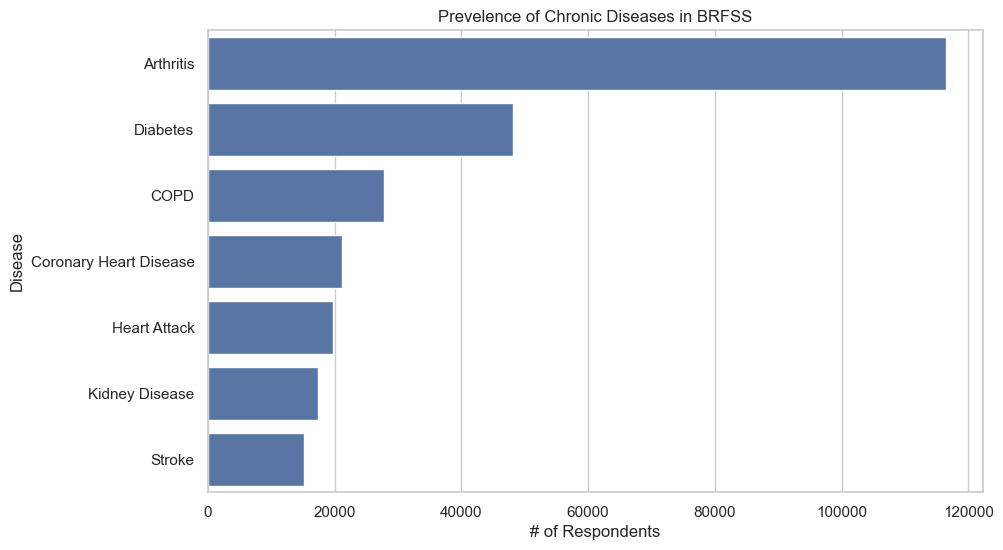

In [250]:
#Disease by Respondents
import seaborn as sns
import matplotlib.pyplot as plt

disease_summary_sorted = disease_summary.sort_values(by='Count',ascending=False)
plt.figure(figsize=(10,6))

sns.barplot(data=disease_summary_sorted,
            x='Count',
            y='Disease')

plt.title('Prevelence of Chronic Diseases in BRFSS')
plt.xlabel('# of Respondents')
plt.ylabel('Disease')

plt.show()


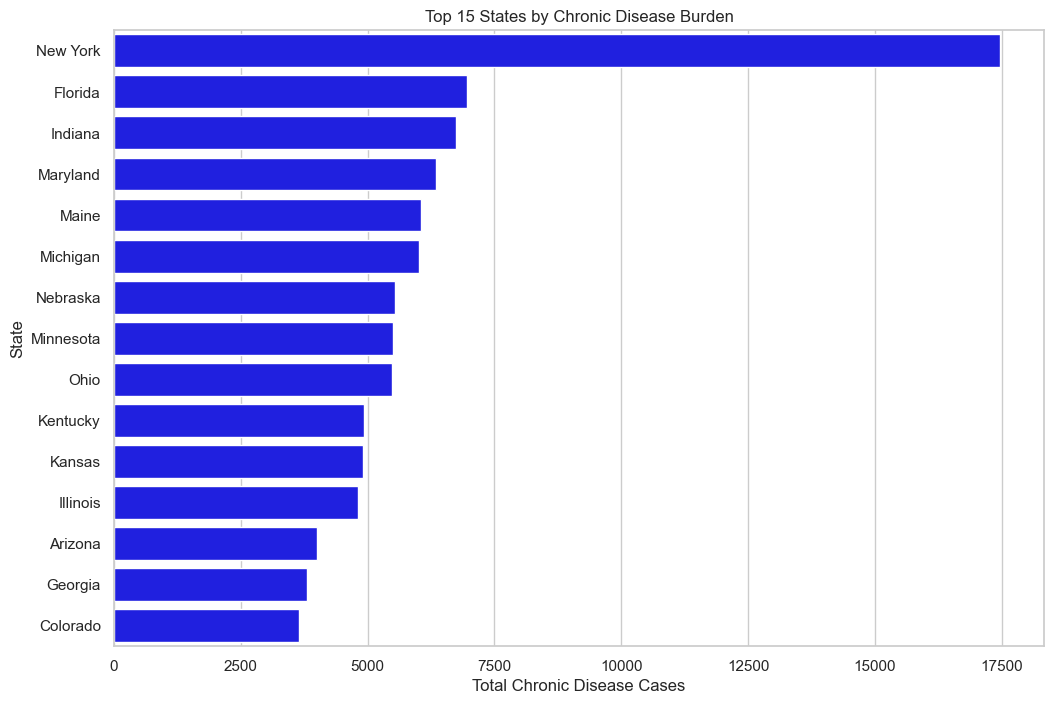

In [251]:
#Disease by State
state_burden = pd.DataFrame({
    
    'Diabetes': chronic_df.groupby('_STATE')['DIABETE4'].apply(lambda x: (x == 1).sum()),
    'Heart Attack': chronic_df.groupby('_STATE')['CVDINFR4'].apply(lambda x: (x == 1).sum()),
    'Coronary Heart Disease': chronic_df.groupby('_STATE')['CVDCRHD4'].apply(lambda x: (x == 1).sum()),
    'Stroke': chronic_df.groupby('_STATE')['CVDSTRK3'].apply(lambda x: (x == 1).sum()),
    'COPD': chronic_df.groupby('_STATE')['CHCCOPD3'].apply(lambda x: (x == 1).sum()),
    'Kidney Disease': chronic_df.groupby('_STATE')['CHCKDNY2'].apply(lambda x: (x == 1).sum()),
    #'Arthritis': chronic_df.groupby('_STATE')['HAVARTH4'].apply(lambda x: (x == 1).sum())   Removed Arthritis
})
#State Code lookup
state_mapping = {
1:'Alabama',
2:'Alaska',
4:'Arizona',
5:'Arkansas',
6:'California',
8:'Colorado',
9:'Connecticut',
10:'Delaware',
11:'District of Columbia',
12:'Florida',
13:'Georgia',
15:'Hawaii',
16:'Idaho',
17:'Illinois',
18:'Indiana',
19:'Iowa',
20:'Kansas',
21:'Kentucky',
22:'Louisiana',
23:'Maine',
24:'Maryland',
25:'Massachusetts',
26:'Michigan',
27:'Minnesota',
28:'Mississippi',
29:'Missouri',
30:'Montana',
31:'Nebraska',
32:'Nevada',
33:'New Hampshire',
34:'New Jersey',
35:'New Mexico',
36:'New York',
37:'North Carolina',
38:'North Dakota',
39:'Ohio',
40:'Oklahoma',
41:'Oregon'
}

#Total Chronic Disease
state_burden['Total_Burden'] = state_burden.sum(axis=1)

#Replace codes with state name
state_burden.index = state_burden.index.map(state_mapping)

#Sort
state_burden = state_burden.sort_values(
    'Total_Burden',
    ascending=False
)
state_burden.head(15)

#Figure
plt.figure(figsize=(12,8))

sns.barplot(
    data=state_burden.head(15),
    x='Total_Burden',
    y=state_burden.head(15).index,
    color='blue')

plt.title('Top 15 States by Chronic Disease Burden')
plt.xlabel('Total Chronic Disease Cases')
plt.ylabel('State')
plt.show()


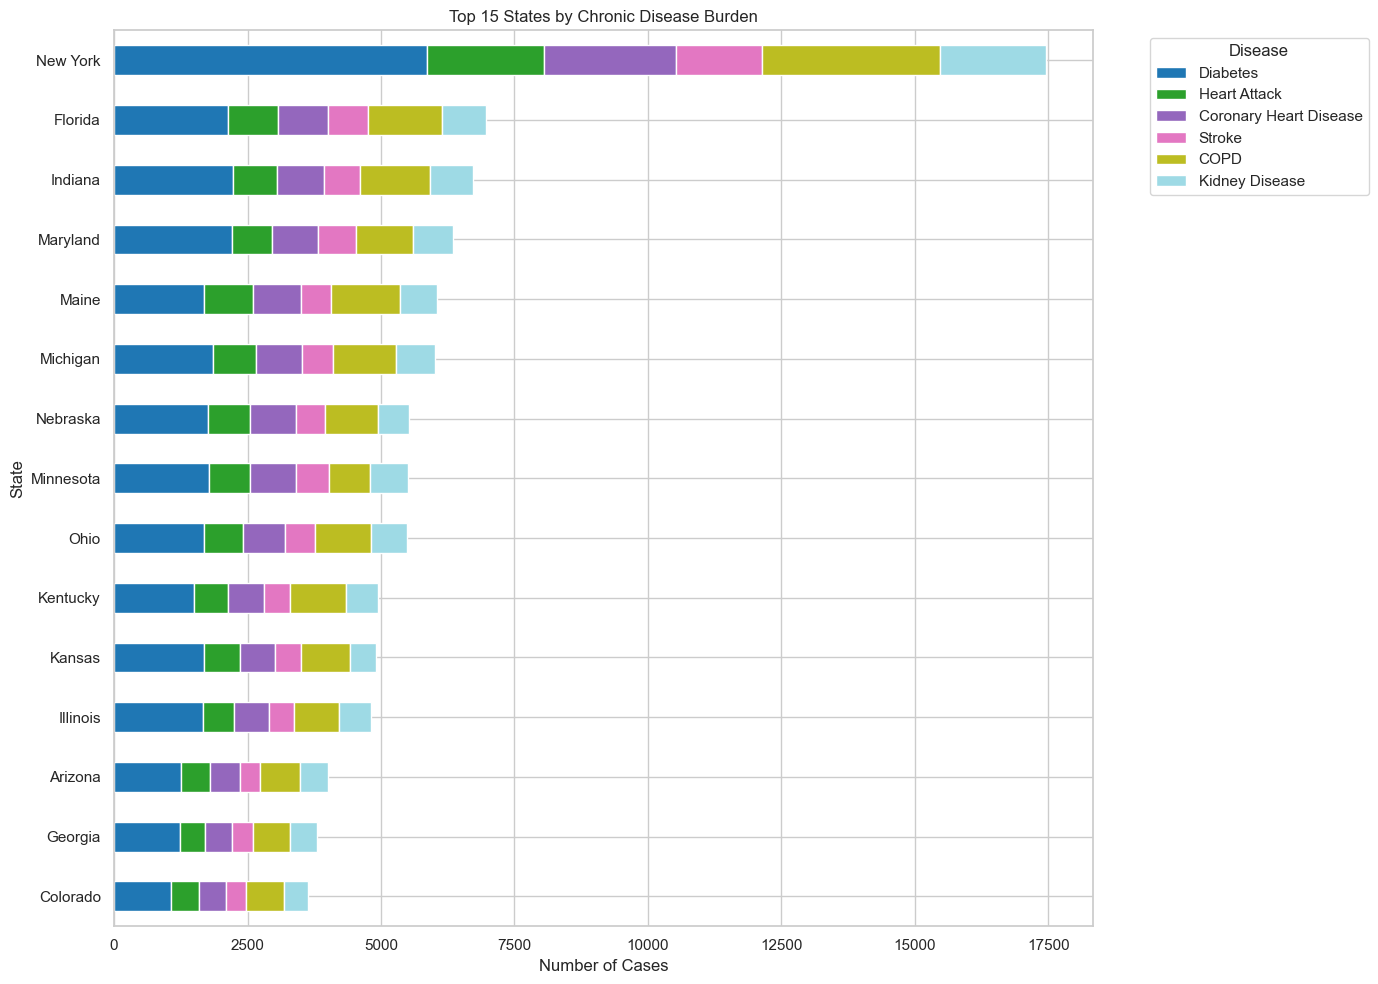

In [252]:
#Stacked Bar by State

#Top 15 by State
top15 = state_burden.head(15)
top15 = top15.iloc[::-1]

#Chronic Disease Columns
disease_cols = [
'Diabetes',
'Heart Attack',
'Coronary Heart Disease',
'Stroke',
'COPD',
'Kidney Disease'
]

#Chart
top15[disease_cols].plot(
kind='barh',
stacked=True,
figsize=(14,10),
colormap='tab20'
)

plt.title('Top 15 States by Chronic Disease Burden')
plt.xlabel('Number of Cases')
plt.ylabel('State')

plt.legend(
title='Disease',
bbox_to_anchor=(1.05, 1),
loc='upper left'
)

plt.tight_layout()
plt.show()


In [253]:
#Conclusion

#The BRFSS dataset provides a view of chronic disease prevalence across a large and diverse population. This dataset consisted of 337,897 survey respondents and 301 variables. The quality of the data was sufficient as there were no duplicate records and view missing values. Analysis of selected chronic diseases shows that Diabetes was the most prevalent condition, followed by COPD, Coronary Heart Disease, Heart Attack, Kidney Disease, and Stroke. The analysis also shows that chronic disease burden varies across geographic regions. State level analysis suggests that New York and Florida as having some of the highest chronic disease burdens among the selected disease categories. Overall, the BRFSS dataset provides a strong foundation to better understanding the distribution of chronic disease across the U.S. These findings combined with the CMS provider data, can support future analysis of whether healthcare provider availability is aligned with population health needs. By joining chronic disease prevalence with provider specialty counts, future analysis can identify regions that may experience provider shortages relative to disease burden and aid to inform healthcare planning, resource allocation, and access to care initiatives.

NHANES

In [254]:
#Data

df_nhanes = pd.read_excel(r"DEMO_L.xlsx")

df_nhanes.shape

(11933, 27)

In [255]:
#Data Type
df_nhanes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 27 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      11933 non-null  int64  
 1   SDDSRVYR  11933 non-null  int64  
 2   RIDSTATR  11933 non-null  int64  
 3   RIAGENDR  11933 non-null  int64  
 4   RIDAGEYR  11933 non-null  int64  
 5   RIDAGEMN  377 non-null    float64
 6   RIDRETH1  11933 non-null  int64  
 7   RIDRETH3  11933 non-null  int64  
 8   RIDEXMON  8860 non-null   float64
 9   RIDEXAGM  2787 non-null   float64
 10  DMQMILIZ  8301 non-null   float64
 11  DMDBORN4  11914 non-null  float64
 12  DMDYRUSR  1875 non-null   float64
 13  DMDEDUC2  7794 non-null   float64
 14  DMDMARTZ  7792 non-null   float64
 15  RIDEXPRG  1503 non-null   float64
 16  DMDHHSIZ  11933 non-null  int64  
 17  DMDHRGND  4115 non-null   float64
 18  DMDHRAGZ  4124 non-null   float64
 19  DMDHREDZ  3746 non-null   float64
 20  DMDHRMAZ  4020 non-null   fl

In [256]:
#Missing Values
df_nhanes.isnull().sum()

SEQN            0
SDDSRVYR        0
RIDSTATR        0
RIAGENDR        0
RIDAGEYR        0
RIDAGEMN    11556
RIDRETH1        0
RIDRETH3        0
RIDEXMON     3073
RIDEXAGM     9146
DMQMILIZ     3632
DMDBORN4       19
DMDYRUSR    10058
DMDEDUC2     4139
DMDMARTZ     4141
RIDEXPRG    10430
DMDHHSIZ        0
DMDHRGND     7818
DMDHRAGZ     7809
DMDHREDZ     8187
DMDHRMAZ     7913
DMDHSEDZ     9806
WTINT2YR        0
WTMEC2YR        0
SDMVSTRA        0
SDMVPSU         0
INDFMPIR     2041
dtype: int64

In [257]:
#Duplicates
df_nhanes.duplicated().sum()

np.int64(0)

In [258]:
#Summary
df_nhanes.describe()

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,DMQMILIZ,DMDBORN4,DMDYRUSR,DMDEDUC2,DMDMARTZ,RIDEXPRG,DMDHHSIZ,DMDHRGND,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR
count,11933.000000,11933.0,11933.000000,11933.000000,11933.000000,377.000000,11933.000000,11933.000000,8860.000000,2787.000000,8301.000000,11914.000000,1875.000000,7794.000000,7792.000000,1503.000000,11933.000000,4115.000000,4124.000000,3746.000000,4020.000000,2127.000000,11933.000000,11933.000000,11933.000000,11933.000000,9892.000000
mean,136344.000000,12.0,1.742479,1.532808,38.317858,11.628647,3.104584,3.320540,1.520203,121.908504,1.916998,1.157378,7.334933,3.804978,1.778491,2.236860,3.242772,1.564277,2.539525,2.171383,1.381095,2.275035,27404.135674,27404.135674,179.918294,1.491746,2.708174
std,3444.904716,0.0,0.437287,0.498943,25.601990,6.805429,1.076346,1.518379,0.499620,67.158655,0.282376,0.364172,15.829158,1.153750,3.101080,0.485254,1.699512,0.495912,0.641094,0.660132,0.681421,0.694050,19449.155209,27962.962514,4.309624,0.499953,1.670119
min,130378.000000,12.0,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,4584.463196,0.000000,173.000000,1.000000,0.000000
25%,133361.000000,12.0,1.000000,1.000000,13.000000,6.000000,3.000000,3.000000,1.000000,66.000000,2.000000,1.000000,3.000000,3.000000,1.000000,2.000000,2.000000,1.000000,2.000000,2.000000,1.000000,2.000000,14331.753594,0.000000,176.000000,1.000000,1.180000
50%,136344.000000,12.0,2.000000,2.000000,37.000000,11.000000,3.000000,3.000000,2.000000,122.000000,2.000000,1.000000,6.000000,4.000000,1.000000,2.000000,3.000000,2.000000,2.000000,2.000000,1.000000,2.000000,21670.185970,21717.849160,180.000000,1.000000,2.500000
75%,139327.000000,12.0,2.000000,2.000000,62.000000,17.000000,4.000000,4.000000,2.000000,179.500000,2.000000,1.000000,6.000000,5.000000,2.000000,3.000000,4.000000,2.000000,3.000000,3.000000,2.000000,3.000000,33831.331556,38341.150005,184.000000,2.000000,4.500000
max,142310.000000,12.0,2.000000,2.000000,80.000000,24.000000,5.000000,7.000000,2.000000,239.000000,7.000000,2.000000,99.000000,9.000000,99.000000,3.000000,7.000000,2.000000,4.000000,3.000000,3.000000,3.000000,170968.343177,227108.296958,187.000000,2.000000,5.000000


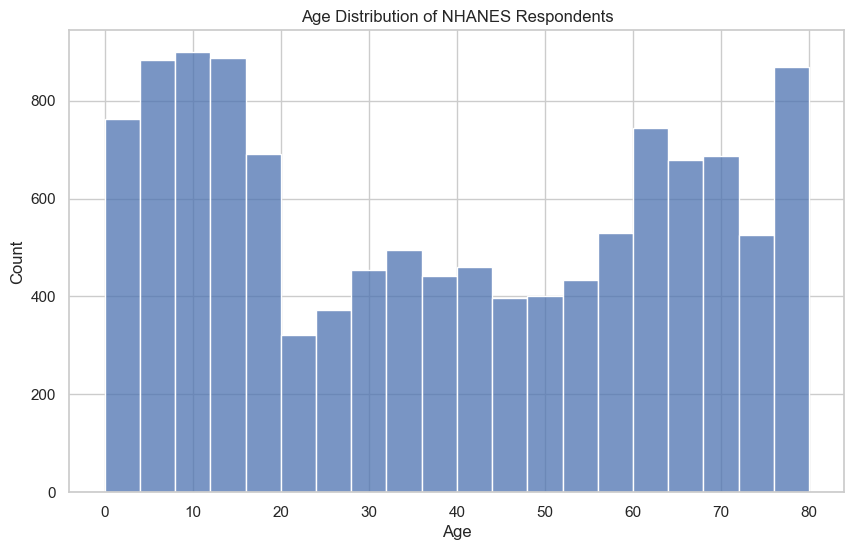

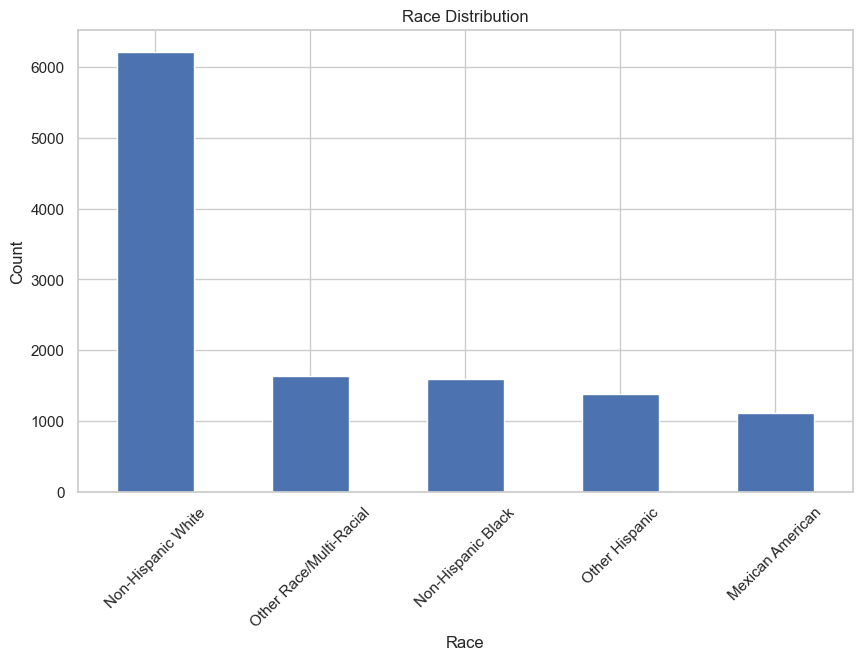

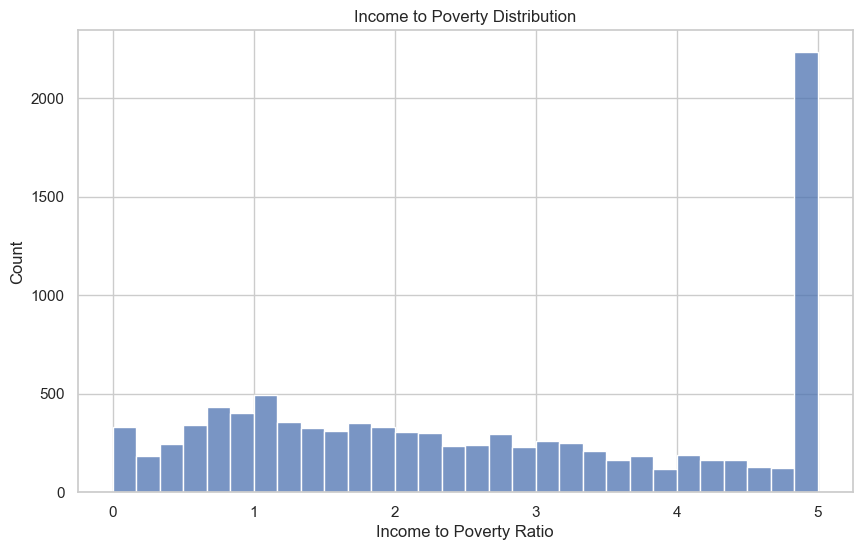

In [259]:
#Analysis

#Age Distribution
plt.figure(figsize=(10,6))

sns.histplot(
    df_nhanes['RIDAGEYR'],
    bins=20
)

plt.title('Age Distribution of NHANES Respondents')
plt.xlabel('Age')
plt.ylabel('Count')

plt.show()

#Race Distribution
race_mapping = {
    1: 'Mexican American',
    2: 'Other Hispanic',
    3: 'Non-Hispanic White',
    4: 'Non-Hispanic Black',
    5: 'Other Race/Multi-Racial'}

race_counts = (df_nhanes['RIDRETH1'].map(race_mapping).value_counts())


race_counts.plot(kind='bar', figsize=(10,6))
plt.title('Race Distribution')
plt.xlabel('Race')
plt.ylabel('Count')
plt.xticks(rotation=45)

plt.show()

#Income to Poverty Distribution
plt.figure(figsize=(10,6))

sns.histplot(
    df_nhanes['INDFMPIR'],
    bins=30
)

plt.title('Income to Poverty Distribution')
plt.xlabel('Income to Poverty Ratio')
plt.ylabel('Count')

plt.show()

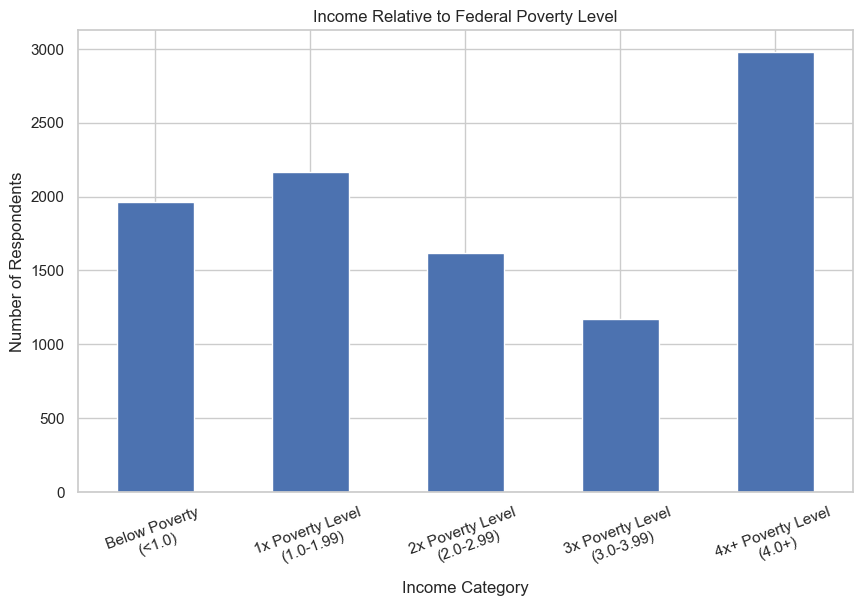

In [260]:
#Grouped Poverty Distribution
income_groups = pd.cut(
    df_nhanes['INDFMPIR'],
    bins=[0,1,2,3,4,5.01], 
    labels=[
        'Below Poverty\n(<1.0)',
        '1x Poverty Level\n(1.0-1.99)',
        '2x Poverty Level\n(2.0-2.99)',
        '3x Poverty Level\n(3.0-3.99)',
        '4x+ Poverty Level\n(4.0+)'
    ],
    include_lowest=True
)
income_groups.value_counts().sort_index()

#Plot
income_groups.value_counts().sort_index().plot(kind='bar',figsize=(10,6))

plt.title('Income Relative to Federal Poverty Level')
plt.xlabel('Income Category')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=20)
plt.show()


In [261]:
#Conclusion

#The National Health and Nutrition Examination Survey (NHANES) contains socioeconomic and demographic data from 11,933 respondents. Demographic variables included age, gender, race, household size, and income to poverty ratios. The dataset shows a diverse population across multiple demographic and socioeconomic groups. Race and ethnicity analysis suggests that Non-Hispanic White respondents represent the largest category. Analysis of the Income to Poverty Ratio, highlights a significant socioeconomic variation among respondents. Roughly 2000 respondents reported household incomes below the federal poverty level, while the largest category reporting incomes at least four times greater than the poverty threshold. These findings suggest that the dataset includes individuals from both economically vulnerable and economically advantaged households. This magnifies the importance of socioeconomic factors when examining healthcare access and health outcomes. Overall, the NHANES dataset provides valuable demographic and socioeconomic information that the blends with the chronic disease findings in the BRFSS dataset. When the BRFSS chronic disease prevalence data and CMS provider availability data, these findings help to support reviewing relationships among socioeconomic status, disease burden, healthcare access, and provider resources.  

# 4. Storytelling With Data graph

Just like last week: choose any graph in the Introduction of Storytelling With Data (p. 1-17). Use matplotlib to reproduce it in a rough way. I don't expect you to spend an enormous amount of time on this; I understand that you likely will not have time to re-create every feature of the graph. However, if you're excited about learning to use matplotlib, this is a good way to do that. You don't have to duplicate the exact values on the graph; just the same rough shape will be enough.  If you don't feel comfortable using matplotlib yet, do the best you can and write down what you tried or what Google searches you did to find the answers.

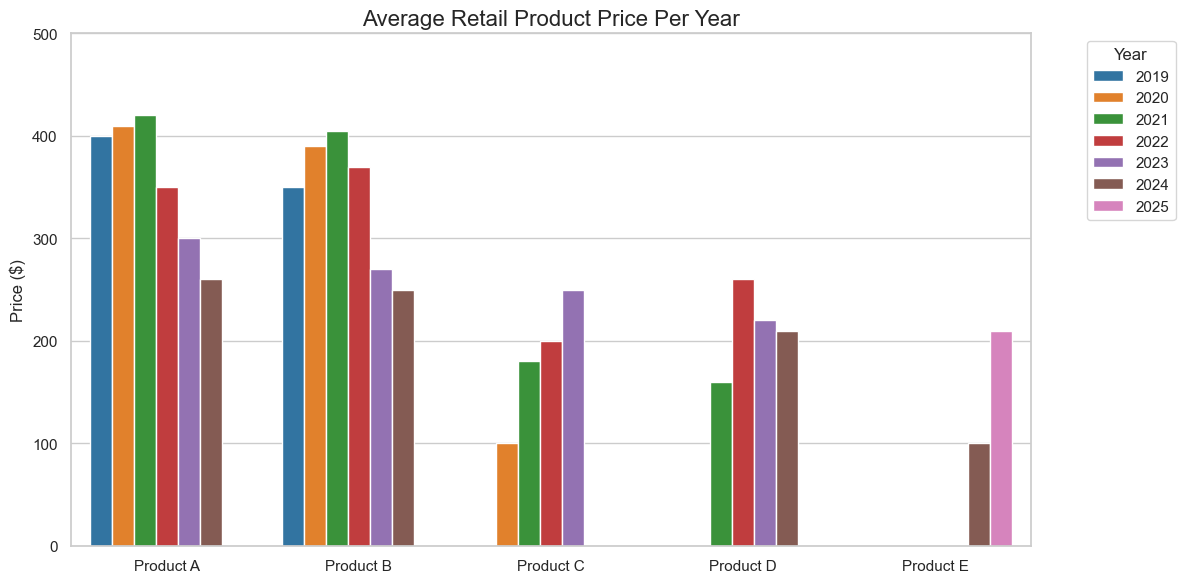

In [262]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#dataset

df = pd.DataFrame({
    'Product': ['Product A', 'Product B', 'Product C', 'Product D', 'Product E'],
    '2019': [400,350,0,0,0],
    '2020': [410,390,100,0,0],
    '2021': [420,405,180,160,0],
    '2022': [350,370,200,260,0],
    '2023': [300,270,250,220,0],
    '2024': [260,250,0,210,100],
    '2025': [0,0,0,0,210]
})

df_long = pd.melt(df, 
                  id_vars='Product', 
                  var_name='Year',
                  value_name='Price')

#Set Seaborn Style
sns.set_theme(style="whitegrid")


# Create Graph
plt.figure(figsize=(12,6))

#Grouped Bar Chart
sns.barplot(
    data=df_long,
    x='Product',
    y='Price',
    hue='Year',
    palette='tab10'
    )

#Format
plt.title('Average Retail Product Price Per Year',
        fontsize=16,)

plt.xlabel('')
plt.ylabel('Price ($)')
plt.ylim(0,500)

#Legend
plt.legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()

plt.show()
